In [1]:
import sys

print("Python version:", sys.version)
print("Python location:", sys.executable)
print("Shelf sight is ready!")



Python version: 3.12.2 (v3.12.2:6abddd9f6a, Feb  6 2024, 17:02:06) [Clang 13.0.0 (clang-1300.0.29.30)]
Python location: /Users/shivabasnet/shelfsight_project/.venv/bin/python
Shelf sight is ready!


In [3]:
from pathlib import Path

# Setup data path
data_path = Path("../data")

# Setup paths to dataset splits
train_path = data_path / "train"
valid_path = data_path / "valid"
test_path = data_path / "test"

# Check whether dataset folder exist
for folder in [train_path, valid_path, test_path]:
    if folder.is_dir():
        print(f"{folder} directory exists. ")
    else:
        print(f"{folder} directory not found!.")

../data/train directory exists. 
../data/valid directory exists. 
../data/test directory exists. 


In [4]:
Path.cwd()

PosixPath('/Users/shivabasnet/shelfsight_project/notebooks')

In [7]:
# Check how many images are in each dataset split
for split, folder in [
    ("Training" , train_path / "images"),
    ("Validation", valid_path / "images"),
    ("Testing" , test_path / "images")
]:
    image_count = len(list(folder.glob("*")))
    print(f"{split} :{image_count}images")

Training :6998images
Validation :2000images
Testing :1000images


In [10]:
# Check how many labels are in each split
for split, folder in [
    ("Training labels:", train_path / "labels"),
    ("Validation labels:", valid_path / "labels"),
    ("Testing labels:", test_path / "labels")
]:
    labels_count = len(list(folder.glob("*")))
    print(f"{split} : {labels_count} labels")

Training labels: : 6998 labels
Validation labels: : 2000 labels
Testing labels: : 1000 labels


Random image path : ../data/train/images/train_102_jpg.rf.b14743b22aae763d3c3cfc1310415eb0.jpg
Image height : 4160
Image width : 2336
Image format : JPEG
Image mode : RGB


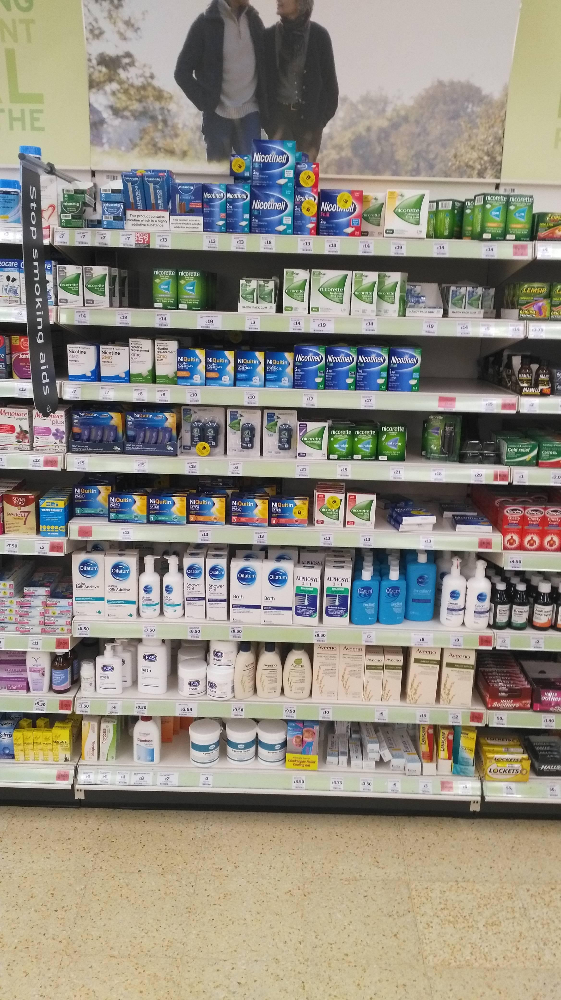

In [ ]:
from PIL import Image
import random

# Set seed
random.seed(42)

# Get all training image paths
image_path_list  = list((train_path / "images").glob("*.jpg"))

# Get the random image path
random_image_path = random.choice(image_path_list)

# Get the image
img = Image.open(random_image_path)

# Print image metadata
print(f"Random image path : {random_image_path}")
print(f"Image height : {img.height}")
print(f"Image width : {img.width}")
print(f"Image format : {img.format}")
print(f"Image mode : {img.mode}")

# Display the image
img

(np.float64(-0.5), np.float64(2335.5), np.float64(4159.5), np.float64(-0.5))

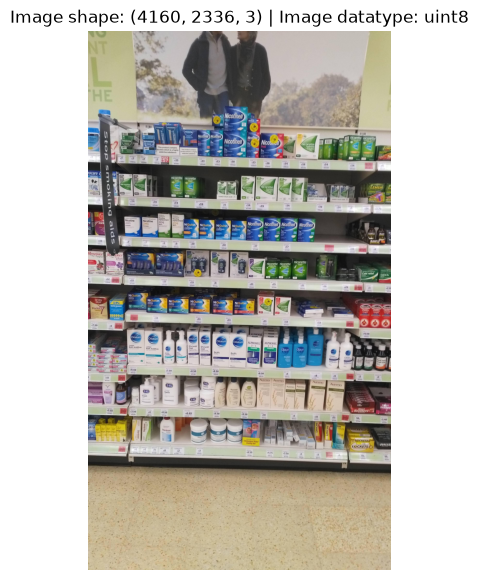

In [19]:
import numpy as np
import matplotlib.pyplot as plt

# Convert PIL image into NumPy array
img_as_array = np.asarray(img)

# Plot the image with matplotlib
plt.figure(figsize=(10, 7))
plt.imshow(img_array)
plt.title(f"Image shape: {img_as_array.shape} | Image datatype: {img_as_array.dtype}")
plt.axis(False)


In [23]:
# Check the random 5 sample images have same dimension or not
import random
from PIL import Image

# set seed
random.seed(42)

# select 5 more random training images
random_image_paths = random.sample(image_path_list, 5 )

# Inspect their dimension
for image_path in random_image_paths:
    img = Image.open(image_path)
    print(f"{image_path.name} : {img.size}")


train_102_jpg.rf.b14743b22aae763d3c3cfc1310415eb0.jpg : (2336, 4160)
train_512_jpg.rf.5007106cab4d21159d8978c72a8ef078.jpg : (2448, 3264)
train_4204_jpg.rf.471a823d0d3fb7ce28b4b9c6cbb07f5a.jpg : (1920, 2560)
train_1293_jpg.rf.8acf4c150a9cc8a451de6865240b267d.jpg : (2560, 1920)
train_5792_jpg.rf.5f2a6d67f2cc5e6b31fbc2aa0da33494.jpg : (2448, 3264)


In [26]:
# Find  all unique  image dimensions on entire training set
unique_image_sizes = set()
for image_path in image_path_list:
    img = Image.open(image_path)
    unique_image_sizes.add(img.size)
print("Unique image dimensions:", len(unique_image_sizes))

for size in sorted(unique_image_sizes):
    print(size)

Unique image dimensions: 41
(480, 640)
(1152, 1920)
(1836, 3264)
(1840, 3264)
(1920, 2560)
(1932, 2576)
(1936, 2592)
(1944, 2592)
(2160, 3840)
(2268, 4032)
(2304, 4096)
(2322, 4128)
(2336, 4160)
(2340, 4160)
(2368, 4208)
(2368, 4224)
(2400, 3200)
(2432, 4320)
(2448, 3264)
(2449, 3265)
(2560, 1920)
(2592, 1936)
(2592, 4608)
(2988, 5312)
(3000, 4000)
(3024, 3024)
(3024, 4032)
(3096, 4128)
(3104, 4192)
(3120, 4160)
(3120, 4208)
(3264, 2448)
(3840, 2160)
(4096, 2304)
(4128, 2322)
(4128, 3096)
(4160, 2336)
(4160, 2340)
(4160, 3120)
(4208, 3120)
(4320, 2432)


In [32]:
import torch
import torchvision

print("PyTorch version:" ,torch.__version__)
print("Torchvision:", torchvision.__version__)

PyTorch version: 2.15.0
Torchvision: 0.29.2


Representation of images sizes in various form

In [ ]:

import numpy as np
from torchvision.transforms import ToTensor

# Convert PIL image into NumPy array
image_as_array = np.asarray(img)

# Convert PIL image into PyTorch tensor
image_as_tensor = ToTensor()(img) # Convert PIL image into PyTorch tensor(C,H, W)

print("PIL image size:", img.size)
print("NumPy image shape:", image_as_array.shape)
print("PyTorch  tensor shape:", image_as_tensor.shape)
print("PyTorch  tensor data type:", image_as_tensor.dtype)


PIL image size: (1920, 2560)
NumPy image shape: (2560, 1920, 3)
PyTorch  tensor shape: torch.Size([3, 2560, 1920])
PyTorch  tensor data type: torch.float32


Verifying the pixel values

In [ ]:

print("Maximum pixel values:", image_as_tensor.max())
print("Minimum pixel values:", image_as_tensor.min())

Maximum pixel values: tensor(1.)
Minimum pixel values: tensor(0.)


Inspecting one YOLO annotation file

In [39]:
# Check train label path folder exist or not
train_label_path = train_path / "labels"

print("Training label folder:", train_label_path)
print("Folder exist:", train_label_path.is_dir())

Training label folder: ../data/train/labels
Folder exist: True


In [40]:
# Get the corresponding label file
label_file_path = train_label_path / f"{random_image_path.stem}.txt"

print(label_file_path)
print("Label file path exist:", label_file_path.is_file())

../data/train/labels/train_102_jpg.rf.b14743b22aae763d3c3cfc1310415eb0.txt
Label file path exist: True


In [49]:
# Open and read the YOLO annotation file
with open(label_file_path, "r") as file:
    label_content = file.read()
print(label_content)


0 0.5252568493150684 0.7466346153846154 0.025684931506849314 0.05096153846153846
0 0.9250856164383562 0.21646634615384616 0.052226027397260275 0.04927884615384615
0 0.0858304794520548 0.744951923076923 0.015839041095890412 0.035096153846153846
0 0.4852311643835616 0.7426682692307692 0.048373287671232876 0.05360576923076923
0 0.613013698630137 0.7615384615384615 0.012842465753424657 0.013942307692307693
0 0.5894691780821918 0.7580528846153847 0.025684931506849314 0.008894230769230769
0 0.4334332191780822 0.7429086538461539 0.055222602739726026 0.05360576923076923
0 0.055008561643835614 0.6013221153846153 0.0526541095890411 0.010817307692307692
0 0.2624143835616438 0.7403846153846154 0.046232876712328765 0.04903846153846154
0 0.19028253424657535 0.7403846153846154 0.030393835616438356 0.04903846153846154
0 0.10573630136986302 0.6024038461538461 0.04452054794520548 0.008653846153846154
0 0.061215753424657536 0.5903846153846154 0.06678082191780822 0.011057692307692308
0 0.6337756849315068 

Inspecting the `data.yaml` file 

In [50]:
# Identify the class name
data_yaml_path = data_path / "data.yaml"

with open(data_yaml_path, "r") as file:
    yaml_content = file.read()

print(yaml_content)

train: ../train/images
val: ../valid/images
test: ../test/images

nc: 1
names: ['object']

roboflow:
  workspace: jacobs-workspace
  project: sku-110k
  version: 6
  license: CC BY 4.0
  url: https://universe.roboflow.com/jacobs-workspace/sku-110k/dataset/6


Understand how many objects are labelled in an image

In [51]:
with open(label_file_path, "r") as file:
    lines = file.readlines()

print("Number of annotations:", len(lines))
print("First annotation:", lines[0].strip())


Number of annotations: 165
First annotation: 0 0.5252568493150684 0.7466346153846154 0.025684931506849314 0.05096153846153846


In [56]:
# Splitting the first annotation
first_annotation = lines[0].strip()
annotation_parts = first_annotation.split()

print(annotation_parts)

['0', '0.5252568493150684', '0.7466346153846154', '0.025684931506849314', '0.05096153846153846']


In [57]:
class_id = int(annotation_parts[0])

print(class_id)

0


In [58]:
x_center = float(annotation_parts[1])

print(x_center)

0.5252568493150684


Parsing YOLO annotations

In [73]:
# Create a function to parse YOLO annotations
def parse_annotation(line):

    annotation_parts = line.split()

    class_id = int(annotation_parts[0])
    x_center = float(annotation_parts[1])
    y_center = float(annotation_parts[2])
    box_width = float(annotation_parts[3])
    box_height = float(annotation_parts[4])

    return class_id, x_center, y_center, box_width, box_height





In [75]:
parsed_annotations = []

for line in lines:
    annotation = parse_annotation(line)
    parsed_annotations.append(annotation)

print("Total parsed annotations:", len(parsed_annotations))
print("First parsed annotations:", parsed_annotations[0])

Total parsed annotations: 165
First parsed annotations: (0, 0.5252568493150684, 0.7466346153846154, 0.025684931506849314, 0.05096153846153846)


In [76]:
first_object = parse_annotation(lines[0])

print(first_object)

(0, 0.5252568493150684, 0.7466346153846154, 0.025684931506849314, 0.05096153846153846)


In [79]:
print("Number of annotations:", len(parsed_annotations))
print("Class id:", set( annotation[0] for annotation in parsed_annotation))



Number of annotations: 165
Class id: {0}


In [81]:
# Checking the YOLO coordinates ranges
for annotation in parsed_annotations:
    class_id, x_center, y_center, box_width, box_height = annotation

    if not(0 <= x_center <= 1):
        print("Invalid x_center:", annotation)

    if not(0 <= y_center <= 1):
        print("Invalid y_center:", annotation)

    if not(0 <= box_width <= 1):
        print("Invalid box_width:", annotation)
    
    if not(0 <= box_height <= 1):
        print("Invalid box_height:", annotation)


print("Annotations values completed.")
print("Total annotations checked:", len(parsed_annotations))

Annotations values completed.
Total annotations checked: 165


Let's confirm the image  and annotations match

In [82]:
print("Image:", random_image_path.name)
print("Label:", label_file_path.name)

print("Image dimensions:", img.size)
print("Number of annotations:", len(parsed_annotations))

Image: train_102_jpg.rf.b14743b22aae763d3c3cfc1310415eb0.jpg
Label: train_102_jpg.rf.b14743b22aae763d3c3cfc1310415eb0.txt
Image dimensions: (1920, 2560)
Number of annotations: 165


Calculate the first bounding box

In [96]:
# Get the first annotation
class_id, x_center, y_center, box_width, box_height = parsed_annotations[0]

# Get the image dimensions
image_width, image_height = img.size

# Convert normalized values into pixels
x_center_px = x_center * image_width
y_center_px = y_center * image_height
box_width_px = box_width * image_width
box_height_px = box_height * image_height

# Calculate the top left corner 
x_min = x_center_px - box_width_px / 2
y_min = y_center_px - box_height_px / 2

print("Box center:", (x_center_px, y_center_px))
print("Box dimensions:",  (box_width_px, box_height_px))
print("Top left corner:", (x_min, y_min))



Box center: (1226.9999999999998, 3106.0)
Box dimensions: (60.0, 212.0)
Top left corner: (1196.9999999999998, 3000.0)


In [97]:
# Reloading the correct image into filename
img = Image.open(random_image_path)

print("Loaded image:", img.filename)
print("Image dimension:", img.size)

Loaded image: ../data/train/images/train_102_jpg.rf.b14743b22aae763d3c3cfc1310415eb0.jpg
Image dimension: (2336, 4160)


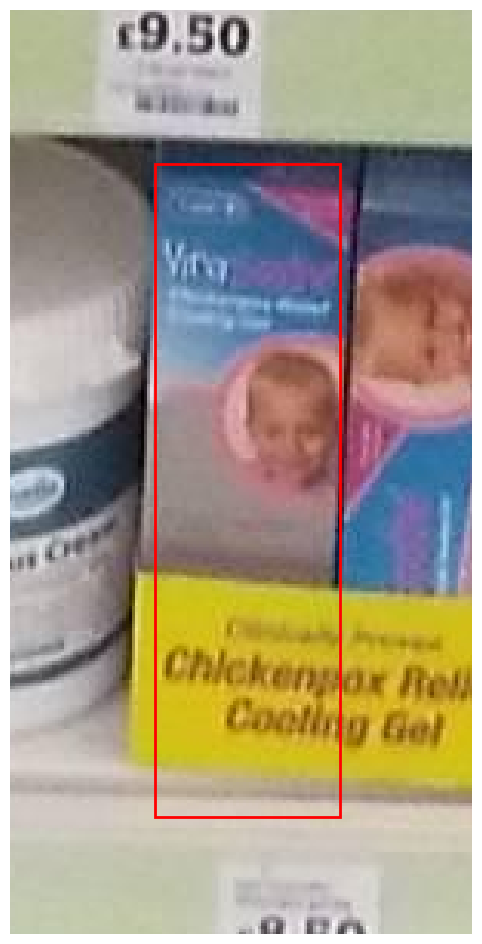

In [99]:
# Draw the first bounding box

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(16, 12))

# Display the image
ax.imshow(img)

# Create a rectangle
rectangle = plt.Rectangle(
    (x_min, y_min),
    box_width_px, 
    box_height_px,
    linewidth = 2,
    edgecolor="red",
    facecolor="none"
)

# Add the rectangle to the image
ax.add_patch(rectangle)
ax.set_xlim(1150, 1300)
ax.set_ylim(3250, 2950)

ax.axis("off");










Checking the bounding box matches with image label or not.

In [95]:
print("Selected image:", random_image_path)
print("Image loaded into image:", img.filename)
print("Image dimension:", img.size)
print("Label file:", label_file_path)

Selected image: ../data/train/images/train_102_jpg.rf.b14743b22aae763d3c3cfc1310415eb0.jpg
Image loaded into image: ../data/train/images/train_102_jpg.rf.b14743b22aae763d3c3cfc1310415eb0.jpg
Image dimension: (2336, 4160)
Label file: ../data/train/labels/train_102_jpg.rf.b14743b22aae763d3c3cfc1310415eb0.txt


Establish the parser is preserving the annotation coreectly or not

In [105]:
# checking the verification between original label and parsed annotations matched or not
with open(label_file_path, "r") as file:
    first_label_line = file.readline().strip()

print("Original label:")
print(first_label_line)

print("\n Parsed annotation:")
print(parsed_annotations[0])

Original label:
0 0.5252568493150684 0.7466346153846154 0.025684931506849314 0.05096153846153846

 Parsed annotation:
(0, 0.5252568493150684, 0.7466346153846154, 0.025684931506849314, 0.05096153846153846)


In [108]:
# Inspect three randomly selected training images
random_image_paths = random.sample(
    list((train_path / "images").glob("*.jpg")), 3
)

for image_path in random_image_paths:
    print(image_path.name)

test_2279_jpg.rf.37812fcdde89ac67eabd750755891ade.jpg
train_5408_jpg.rf.4f03609d887ad181eb810e35045d8778.jpg
train_4541_jpg.rf.25cd399005043db286fc3926e866500d.jpg


In [109]:
print("Training image folder:", train_path / "images")
print("Number of training images:", len(list((train_path / "images").glob("*.jpg"))))

print("\nSelected image paths: ")
for image_path in random_image_paths:
    print(image_path)

Training image folder: ../data/train/images
Number of training images: 6998

Selected image paths: 
../data/train/images/test_2279_jpg.rf.37812fcdde89ac67eabd750755891ade.jpg
../data/train/images/train_5408_jpg.rf.4f03609d887ad181eb810e35045d8778.jpg
../data/train/images/train_4541_jpg.rf.25cd399005043db286fc3926e866500d.jpg


Finding the number of testfile name under training images folder

In [110]:
test_named_files = list((train_path / "images").glob("test_*.jpg"))

print("Test named files inside training folder:", len(test_named_files))

for file_path in test_named_files[:10]:
    print(file_path.name)

Test named files inside training folder: 1764
test_2418_jpg.rf.267142cf4b801e79d363eb2165ba8f94.jpg
test_940_jpg.rf.b58a1f24222fc12bc899ded9b9a77d16.jpg
test_521_jpg.rf.f692c7aa22fab07e96ee646ad973555a.jpg
test_1195_jpg.rf.f1c9930950a7133e705321ab89574b60.jpg
test_1675_jpg.rf.105c6790e20d49aa6e4f83f5c4e81336.jpg
test_1302_jpg.rf.feec4e6903365ad7ef9c7e11d578101d.jpg
test_2273_jpg.rf.0161b12989ac0c757aa3ee41005248ea.jpg
test_2237_jpg.rf.79b9b10a222bff6cb82ab8a0c7d42799.jpg
test_2217_jpg.rf.b0b46bbe266c87b3e4090db923c0d1fb.jpg
test_182_jpg.rf.d1930aa04e061b0b755d581036f1de7e.jpg


Checking the duplicate images across the split

In [112]:
for split_name, split_path in [
    ("Training", train_path),
    ("Validation", valid_path),
    ("Testing", test_path)
]:
    image_files = list((split_path / "images").glob("*.jpg"))

    test_prefix_count = sum(
        image.name.startswith("test_")
        for image in image_files
    )

    train_prefix_count = sum(
        image.name.startswith("train_")
        for image in image_files
    )

    print(f"\n{split_name}")
    print("Total images:", len(image_files))
    print("Names starting with test_:", test_prefix_count)
    print("Names starting with train_:", train_prefix_count)


Training
Total images: 6998
Names starting with test_: 1764
Names starting with train_: 4901

Validation
Total images: 2000
Names starting with test_: 500
Names starting with train_: 1391

Testing
Total images: 1000
Names starting with test_: 247
Names starting with train_: 704


Checking the identical filenames acrss the split

In [113]:
train_files = {
    path.name for path in (train_path / "images").glob("*.jpg")
}

valid_files = {
    path.name for path in (valid_path / "images").glob("*.jpg")
}

test_files = {
    path.name for path in (test_path / "images").glob("*.jpg")
}

print("Train and validation overlap:", len(train_files & valid_files))
print("Train and test overlap:", len(train_files & test_files))
print("Valid and test files:", len(valid_files & test_files))

Train and validation overlap: 0
Train and test overlap: 0
Valid and test files: 0


Select three random images for training dataset and inspect their with YOLO boinding boxes

By selecting three random images we can identify the annotation problems and inspect their contents and annotations.


In [114]:
# Select the three random training images 
random_image_paths = random.sample(
    list((train_path / "images").glob("*.jpg")), 3
)

for image_path in random_image_paths:
    print(image_path.name)

train_5971_jpg.rf.cf716273cd930631e632fcabdf53083b.jpg
test_631_jpg.rf.9293458159a3b2032070eb6940254633.jpg
train_386_jpg.rf.121741c20a3706797c8941297369a772.jpg


In [115]:
for image_path in random_image_paths:
    label_path = train_path / "labels" / f"{image_path.stem}.txt"

    print("Image:", image_path.name)
    print("Label exists:", label_path.is_file())
    print("-" * 50)


Image: train_5971_jpg.rf.cf716273cd930631e632fcabdf53083b.jpg
Label exists: True
--------------------------------------------------
Image: test_631_jpg.rf.9293458159a3b2032070eb6940254633.jpg
Label exists: True
--------------------------------------------------
Image: train_386_jpg.rf.121741c20a3706797c8941297369a772.jpg
Label exists: True
--------------------------------------------------


In [116]:
data_yaml_path = data_path / "data.yaml"

print(data_yaml_path)
print("Configuration file exists:", data_yaml_path.is_file())

../data/data.yaml
Configuration file exists: True


Reading the Dataset Configuration

We locate and read the data.yaml file using python. This allows us  to access dataset settings programmatically.

In [117]:
with open(data_yaml_path, "r") as file:
    yaml_content = file.read()

print(yaml_content)

train: ../train/images
val: ../valid/images
test: ../test/images

nc: 1
names: ['object']

roboflow:
  workspace: jacobs-workspace
  project: sku-110k
  version: 6
  license: CC BY 4.0
  url: https://universe.roboflow.com/jacobs-workspace/sku-110k/dataset/6


In [118]:
import yaml 

with open (data_yaml_path, "r") as file:
    dataset_config = yaml.safe_load(file)

print(dataset_config)



{'train': '../train/images', 'val': '../valid/images', 'test': '../test/images', 'nc': 1, 'names': ['object'], 'roboflow': {'workspace': 'jacobs-workspace', 'project': 'sku-110k', 'version': 6, 'license': 'CC BY 4.0', 'url': 'https://universe.roboflow.com/jacobs-workspace/sku-110k/dataset/6'}}


In [120]:
print("Training images:", dataset_config["train"])
print("Validation images:", dataset_config["val"])
print("Testing images:", dataset_config["test"])
print("Number of classes:", dataset_config["nc"])
print("Class names:", dataset_config["names"])

Training images: ../train/images
Validation images: ../valid/images
Testing images: ../test/images
Number of classes: 1
Class names: ['object']


In [129]:
# Verify the image paths
yaml_directory = data_path

train_images_path = yaml_directory / "train" / "images"
valid_images_path = yaml_directory / "valid" / "images"
test_images_path = yaml_directory / "test" / "images"

print("Training folder exists:", train_images_path.is_dir())
print("Validation folder exists:", valid_images_path.is_dir())
print("Testing folder exists:", test_images_path.is_dir())

Training folder exists: True
Validation folder exists: True
Testing folder exists: True


In [130]:
print("Training path:", train_images_path.resolve())
print("Validation path:", valid_images_path.resolve())
print("Testing path:", test_images_path.resolve())

Training path: /Users/shivabasnet/shelfsight_project/data/train/images
Validation path: /Users/shivabasnet/shelfsight_project/data/valid/images
Testing path: /Users/shivabasnet/shelfsight_project/data/test/images


In [128]:
for folder in data_path.iterdir():
    print(folder.name)

README.roboflow.txt
valid
README.dataset.txt
test
data.yaml
train


Dataset Preparation Complete

Dataset configuration was successfully read and parsed.
Training, validation and testing  images directories were verified.
The dataset is ready for model setup.

